# **Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import math

import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE

from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report,roc_auc_score,roc_curve
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# **LOADING DATA**

In [42]:
df = pd.read_csv("/content/drive/MyDrive/ict/heart_disease.csv")

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [43]:
# Displaying last 5 rows

df.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1
1024,54,1,0,120,188,0,1,113,0,1.4,1,1,3,0


In [44]:
# Shape of the data

df.shape

(1025, 14)

In [45]:
# Datatypes
df.dtypes

,0
age,int64
sex,int64
cp,int64
trestbps,int64
chol,int64
fbs,int64
restecg,int64
thalach,int64
exang,int64
oldpeak,float64


In [46]:
# Checking missing values

df.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


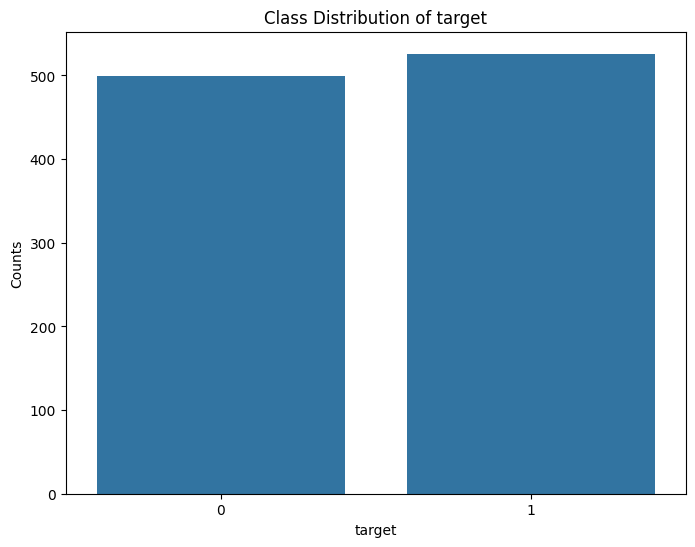

In [47]:
# Checking the class imbalance

values_grade = df['target'].value_counts()

plt.figure(figsize=(8, 6))
sns.barplot(x=values_grade.index, y=values_grade.values)

plt.xlabel("target")
plt.ylabel("Counts")
plt.title("Class Distribution of target")
plt.show()

# **OUTLIER TREATMENT**

In [9]:
# List the few columns you WANT to keep
columns_to_keep = df.columns
# Find all columns that are NOT in your keep list
columns_to_drop = [col for col in df.columns if col not in columns_to_keep]

# Drop all remaining columns in-place
df.drop(columns=columns_to_drop, inplace=True)

In [10]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


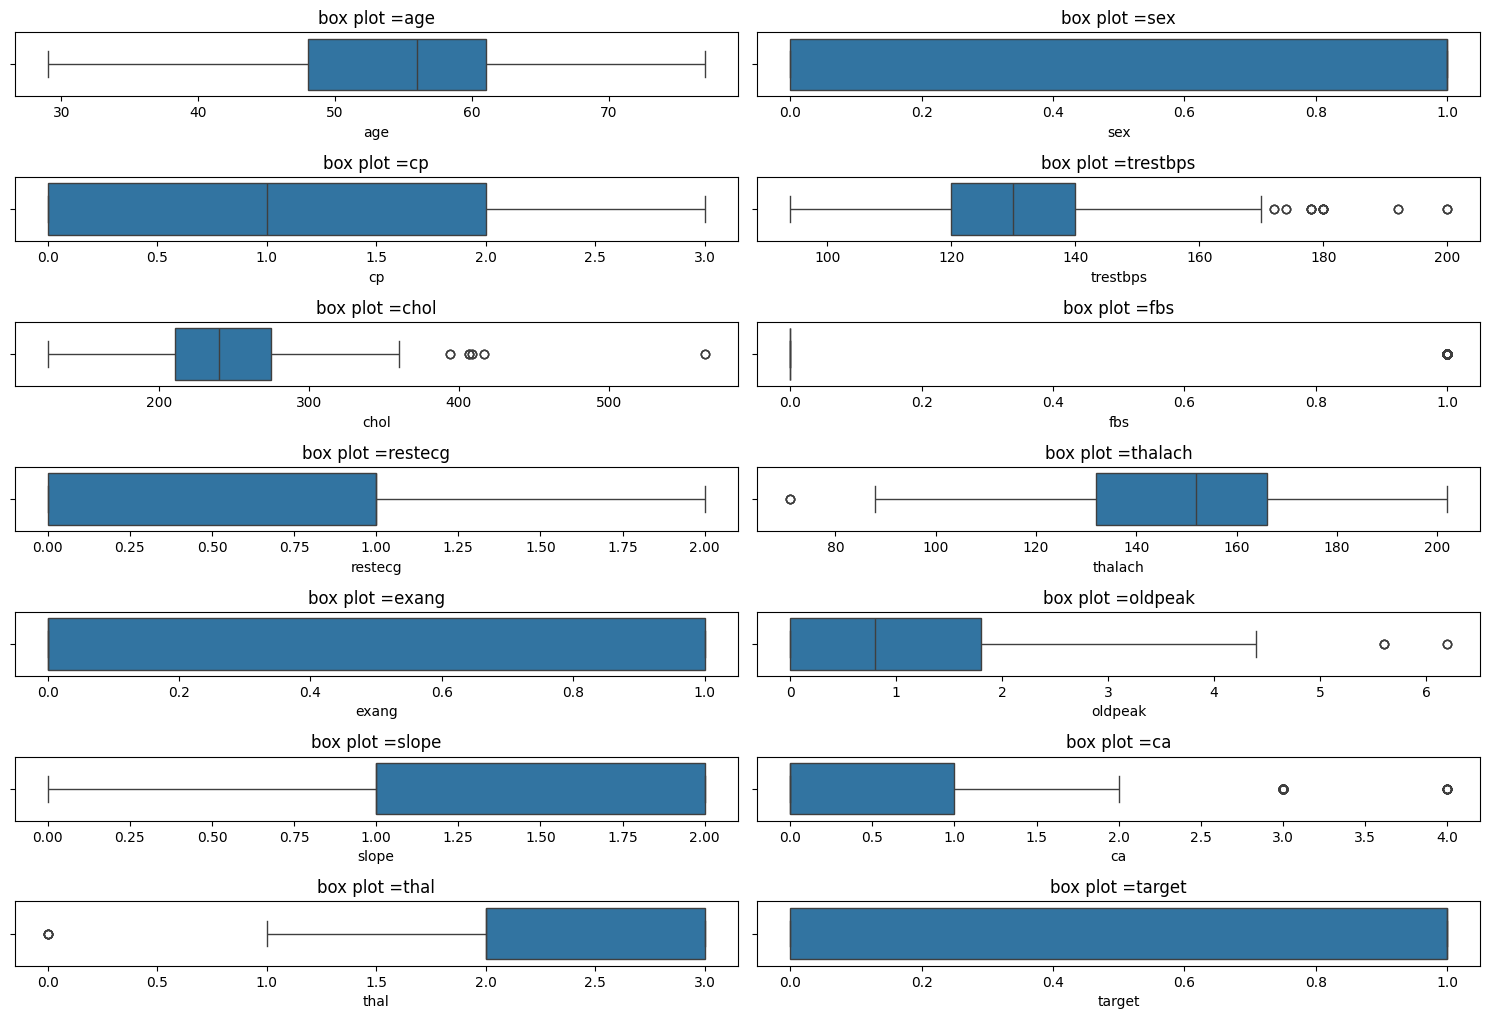

In [13]:
columns=df.columns
plt.figure(figsize=(15,20))
for i,col in enumerate(columns):
    plt.subplot(len(columns),2,i+1)
    sns.boxplot(x=df[col])
    plt.title(f"box plot ={col}")
plt.tight_layout()
plt.show()

In [14]:
columns = [
    'trestbps',
    'chol',
    'fbs','thalach','oldpeak','ca','thal',
]

for col in columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr

    # Replace outliers with upper and lower boundary limits
    df[col] = df[col].clip(lower=lower, upper=upper)


In [15]:
df[col]=df[col].clip(upper=upper,lower=lower)# to replace the value of outiler with the

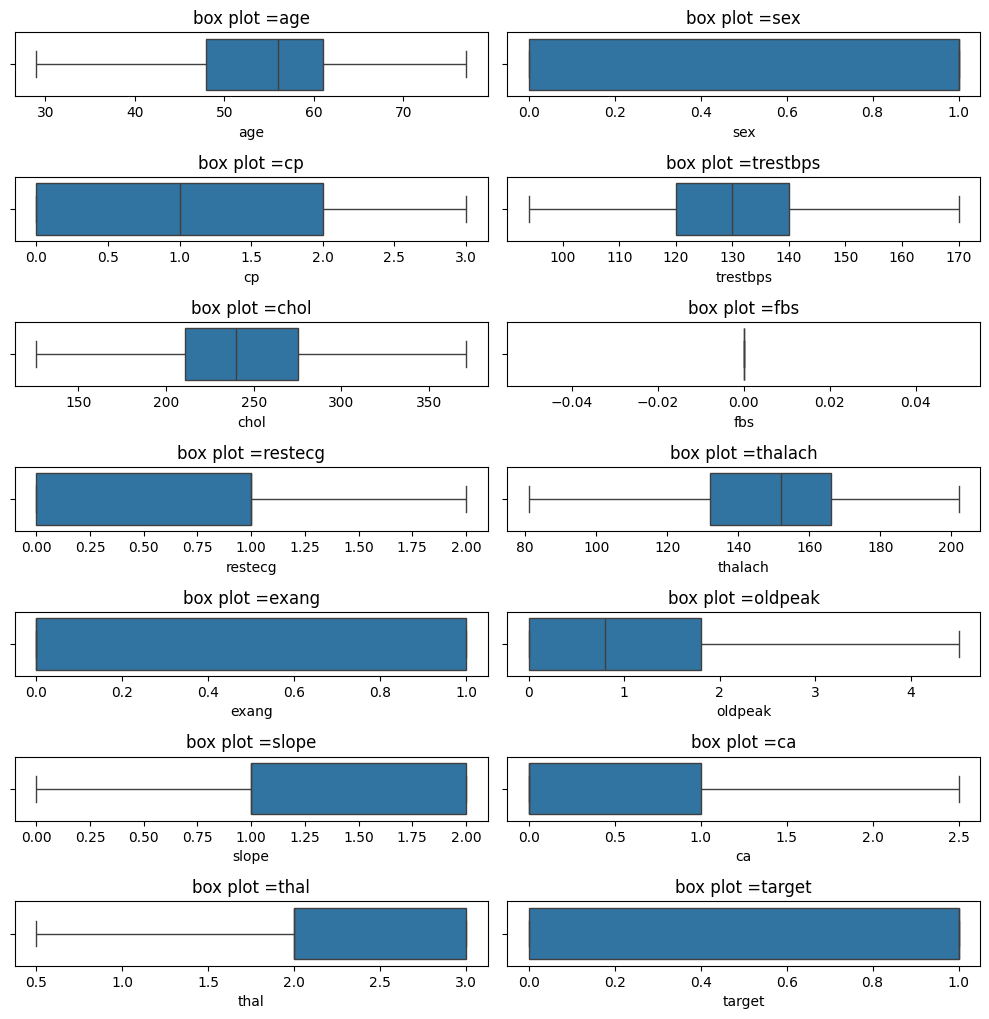

In [16]:
columns=df.columns
plt.figure(figsize=(10,20))
for i,col in enumerate(columns):
    plt.subplot(len(columns),2,i+1)
    sns.boxplot(x=df[col])
    plt.title(f"box plot ={col}")
plt.tight_layout()
plt.show()

# All colunms are numerical values

#  regression

In [21]:
target_data_reg = df["chol"]


# Extracting target data's name
target = target_data_reg.name

## **spliting**

In [22]:
X =df.drop(columns=["chol"])
y = df["chol"]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [25]:
from sklearn.svm import SVR

## MODEL SELECTION

In [28]:
rf= RandomForestRegressor()
lr = LinearRegression()
svm = SVR()

## Model training

In [30]:
rf.fit(X_train,y_train)

svm.fit(X_train, y_train)
lr.fit(X_train,y_train)

LinearRegression()

## MODEL evaluations

### random

In [31]:
y_predr = rf.predict(X_test)
y_predr

array([216.65, 241.23, 288.8 , 246.79, 255.79, 263.37, 247.84, 231.02,
       251.39, 174.94, 297.92, 312.4 , 281.17, 136.08, 194.94, 242.46,
       258.38, 163.14, 211.74, 240.14, 289.66, 247.26, 280.58, 311.31,
       289.66, 175.  , 260.99, 222.99, 327.93, 324.04, 218.83, 287.23,
       229.77, 241.23, 231.85, 222.99, 289.66, 296.53, 159.25, 223.55,
       231.02, 234.37, 197.71, 280.58, 231.06, 227.23, 188.49, 234.46,
       223.54, 235.  , 288.88, 253.84, 240.03, 206.99, 260.99, 159.25,
       269.33, 221.99, 222.89, 212.73, 245.75, 222.49, 327.93, 235.  ,
       267.35, 169.66, 198.33, 254.  , 227.23, 252.67, 202.54, 327.93,
       204.84, 233.29, 242.85, 257.08, 247.84, 267.41, 259.68, 266.06,
       220.5 , 181.  , 323.09, 328.43, 242.85, 323.15, 297.92, 214.93,
       220.5 , 324.04, 229.93, 240.14, 208.34, 266.63, 201.46, 204.03,
       254.  , 310.7 , 291.34, 220.51, 322.15, 264.9 , 277.37, 279.89,
       200.27, 221.59, 221.99, 228.22, 248.65, 262.05, 222.89, 262.05,
      

In [32]:
mean_sq_r= mean_squared_error(y_test,y_predr)
mean_ab_r = mean_absolute_error(y_test,y_predr)
r2_r = r2_score(y_test,y_predr)
print(mean_sq_r,mean_ab_r,r2_r)

164.02981414634144 8.53351219512195 0.932206062292053


### liner

In [33]:
y_predl = lr.predict(X_test)
y_predl

array([260.72669108, 239.37104694, 263.44043024, 243.32714247,
       257.78589129, 277.03949929, 242.11261195, 261.69708299,
       221.89532697, 254.60293486, 248.72781842, 259.57827224,
       215.75093831, 241.02189638, 238.65635421, 274.07422239,
       247.2418695 , 219.09085205, 237.31979159, 236.24339085,
       264.44593531, 257.79807541, 247.33633347, 232.84809307,
       264.44593531, 213.21061218, 237.13752716, 226.9556107 ,
       279.7061162 , 285.69722168, 225.39833952, 249.87655336,
       227.63487427, 239.37104694, 225.16778764, 247.2193197 ,
       264.44593531, 244.29940415, 251.61477493, 219.59350925,
       261.69708299, 251.70135978, 241.57969623, 247.33633347,
       275.78463687, 232.0769639 , 224.13507093, 247.63381454,
       244.70571202, 233.45979334, 212.77173944, 253.37461609,
       260.9511209 , 251.56580111, 237.13752716, 251.61477493,
       271.39167581, 257.17596468, 242.69107485, 244.34067612,
       199.16181623, 226.42904068, 279.7061162 , 233.45

In [34]:
mean_sq_l= mean_squared_error(y_test,y_predl)
mean_ab_l = mean_absolute_error(y_test,y_predl)
r2_l = r2_score(y_test,y_predl)
print(mean_sq_l,mean_ab_l,r2_l)

2329.903882912538 38.584871795326244 0.037044823066396004


### SVM

In [35]:
y_predsvm = svm.predict(X_test)
y_predsvm

array([238.80117655, 241.82924519, 242.39979728, 237.60313167,
       239.12721202, 242.3593979 , 243.20724802, 241.31904765,
       236.85787467, 243.74880529, 237.18505274, 243.76763679,
       236.97769659, 239.73522979, 243.02648825, 238.10976075,
       240.07067378, 235.56467182, 241.66870718, 239.74898508,
       239.01450518, 240.49941787, 238.38576607, 241.92553786,
       239.01450518, 237.3178126 , 239.90283288, 238.68436893,
       241.59891752, 238.7755441 , 240.80600814, 240.7283525 ,
       236.28665061, 241.82924519, 237.44089304, 238.79629981,
       239.01450518, 239.66539151, 241.24245781, 236.57795935,
       241.31904765, 242.12514975, 240.37136618, 238.38576607,
       243.28351472, 243.18461434, 239.2003113 , 237.17419818,
       238.04142496, 242.63526182, 237.83406544, 241.19998289,
       240.70647428, 239.94869934, 239.90283288, 241.24245781,
       237.26799759, 241.37122687, 239.41607473, 239.59622333,
       235.69959147, 239.94065177, 241.59891752, 242.63

In [36]:
mean_sq_svm= mean_squared_error(y_test,y_predsvm)
mean_ab_svm = mean_absolute_error(y_test,y_predsvm)
r2_svm = r2_score(y_test,y_predsvm)
print(mean_sq_svm,mean_ab_svm,r2_svm)

2465.921099440408 39.45853169830353 -0.019171437084164022


### result

In [39]:
# Create a comparison DataFrame
results_df = pd.DataFrame({
    'Model': ['Random Forest', 'Linear Regression', 'SVM'],
    'MSE': [mean_squared_error(y_test, rf.predict(X_test)), mean_sq_l, mean_sq_svm],
    'MAE': [mean_absolute_error(y_test, rf.predict(X_test)), mean_ab_l, mean_ab_svm],
    'R2_Score': [r2_score(y_test, rf.predict(X_test)), r2_l, r2_svm]
}
)
# Find and print the best model (highest R2 Score)
best_model = results_df.loc[results_df['R2_Score'].idxmax()]
print("\n--- Best Model ---")
print(f"Model Name: {best_model['Model']}")
print(f"Highest R2 Score: {best_model['R2_Score']:.4f}")
print(f"Lowest MSE: {best_model['MSE']:.4f}")


--- Best Model ---
Model Name: Random Forest
Highest R2 Score: 0.9322
Lowest MSE: 164.0298


# Classification

In [40]:
target_data_reg = df["target"]


# Extracting target data's name
target = target_data_reg.name

## Spliting

In [41]:
X =df.drop(columns=["target"])
y = df["target"]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## import models

In [48]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

In [60]:
rc = RandomForestClassifier(random_state=42)
knn = KNeighborsClassifier()
lo = LogisticRegression(max_iter=1000)

## model training

In [61]:
rc.fit(X_train, y_train)
knn.fit(X_train, y_train)
lo.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

## Model evaluations

In [62]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

### random class

In [63]:
y_pred_rc = rf.predict(X_test)

In [64]:
accuracy_rc = accuracy_score(y_test, y_pred_rc)
precision_rc = precision_score(y_test, y_pred_rc)
recall_rc = recall_score(y_test, y_pred_rc)
f1_rc = f1_score(y_test, y_pred_rc)

print("Accuracy :", accuracy_rc)
print("Precision:", precision_rc)
print("Recall   :", recall_rc)
print("F1 Score :", f1_rc)

Accuracy : 0.9853658536585366
Precision: 1.0
Recall   : 0.970873786407767
F1 Score : 0.9852216748768473


### knn

In [65]:
y_pred_knn = knn.predict(X_test)

In [66]:
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)

print("Accuracy :", accuracy_knn)
print("Precision:", precision_knn)
print("Recall   :", recall_knn)
print("F1 Score :", f1_knn)

Accuracy : 0.7365853658536585
Precision: 0.7333333333333333
Recall   : 0.7475728155339806
F1 Score : 0.7403846153846154


### logistic

In [67]:
y_pred_lo = lo.predict(X_test)

In [68]:
accuracy_lo = accuracy_score(y_test, y_pred_lo)
precision_lo = precision_score(y_test, y_pred_lo)
recall_lo = recall_score(y_test, y_pred_lo)
f1_lo= f1_score(y_test, y_pred_lo)

print("Accuracy :", accuracy_lo)
print("Precision:", precision_lo)
print("Recall   :", recall_lo)
print("F1 Score :", f1_lo)

Accuracy : 0.8
Precision: 0.75
Recall   : 0.9029126213592233
F1 Score : 0.8193832599118943


### result

In [71]:
# Define evaluation function
def get_metrics(y_true, y_pred):
    return [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, average='weighted'),
        recall_score(y_true, y_pred, average='weighted'),
        f1_score(y_true, y_pred, average='weighted')
    ]

# Build comparison DataFrame using your defined variable names
eval_results = pd.DataFrame({
    'Model': ['Random Forest', 'KNN', 'Logistic Regression'],
    'Accuracy': [get_metrics(y_test, y_pred_rc)[0], get_metrics(y_test, y_pred_knn)[0], get_metrics(y_test, y_pred_lo)[0]],
    'Precision': [get_metrics(y_test, y_pred_rc)[1], get_metrics(y_test, y_pred_knn)[1], get_metrics(y_test, y_pred_lo)[1]],
    'Recall': [get_metrics(y_test, y_pred_rc)[2], get_metrics(y_test, y_pred_knn)[2], get_metrics(y_test, y_pred_lo)[2]],
    'F1 Score': [get_metrics(y_test, y_pred_rc)[3], get_metrics(y_test, y_pred_knn)[3], get_metrics(y_test, y_pred_lo)[3]]
})

print(eval_results)

# Find best model based on Accuracy
best_model = eval_results.loc[eval_results['Accuracy'].idxmax()]
print("\n--- Best Model (Highest Accuracy) ---")
print(f"Model: {best_model['Model']}")
print(f"Accuracy: {best_model['Accuracy']:.4f}")
print(f"F1 Score: {best_model['F1 Score']:.4f}")

                 Model  Accuracy  Precision    Recall  F1 Score
0        Random Forest  0.985366   0.985784  0.985366  0.985364
1                  KNN  0.736585   0.736650  0.736585  0.736548
2  Logistic Regression  0.800000   0.812963  0.800000  0.797776

--- Best Model (Highest Accuracy) ---
Model: Random Forest
Accuracy: 0.9854
F1 Score: 0.9854
